# 8장. 작은 데이터 분석 프로젝트 완성하기

이 노트북은 **질문 → 원본 데이터 점검 → 전처리 → PK/FK 검증 → 안전한 병합 → completed 범위 집계 → 총합 대조 → 시각화 → 보고서 → 최종 Validation**을 하나의 재현 가능한 프로젝트로 연결합니다.

> 코드가 끝까지 실행되었다는 사실만으로 프로젝트가 검증된 것은 아닙니다. 같은 의미의 숫자와 공개 산출물이 정해 둔 기준을 함께 통과해야 합니다.


## 학습 목표

- 원본 데이터를 보존하며 전처리합니다.
- 주요 PK의 결측·중복과 FK 미매칭을 확인합니다.
- `validate`와 `indicator` 관점으로 병합 결과를 검증합니다.
- `line_total = quantity × unit_price`를 다시 확인합니다.
- 금액성 분석은 `order_status == "completed"` 범위를 사용합니다.
- 카테고리·월·고객 금액 합계를 같은 source total과 대조합니다.
- 날짜 오류로 월별 금액이 누락되지 않는지 확인합니다.
- 공개 고객 결과에서 원본 고객 ID와 직접 식별정보를 제거합니다.
- 결과 CSV, 그래프, Markdown 보고서와 PASS/FAIL Evidence를 저장합니다.
- 전체 파이프라인을 다시 실행해 재현성을 확인합니다.


## 제출 정보
- 이름: 전해린
- GitHub ID: Haerin03
- 작성일: 2026.10.28
- 최종 Notebook URL: https://github.com/Haerin03/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb

## 1. 프로젝트 루트와 출력 폴더 설정

VS Code에서 현재 작업 폴더가 프로젝트 루트 또는 `notebooks`일 수 있으므로 상위 폴더를 탐색합니다.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "scripts").exists():
            return candidate
    raise FileNotFoundError("프로젝트 루트 폴더를 찾을 수 없습니다.")


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

for path in [PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Python 실행 파일:", sys.executable)
print("프로젝트 루트:", PROJECT_ROOT)
print("원본 데이터 폴더:", RAW_DIR)
print("보고서 폴더:", REPORT_DIR)


Python 실행 파일: c:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\.venv\Scripts\python.exe
프로젝트 루트: C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study
원본 데이터 폴더: C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\data\raw
보고서 폴더: C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\reports


## 2. 프로젝트 함수 불러오기

Notebook과 일괄 실행 스크립트가 같은 `src.midterm_project` 함수를 사용하도록 하여 계산 기준이 어긋나는 문제를 줄입니다.


In [2]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    FORBIDDEN_CUSTOMER_COLUMNS,
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    build_project_validation,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)


## 3. 원본 데이터 확인

프로젝트는 `data/raw`의 원본 4개 파일에서 시작합니다. 파일이 없다면 프로젝트 루트에서 `python scripts/generate_sample_data.py`를 먼저 실행합니다.


In [3]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicated rows:", int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


## 4. 원본을 보존하며 전처리

`preprocess_sales_data()`는 원본 DataFrame을 직접 수정하지 않고 전처리된 복사본을 반환합니다. 전처리 전후 행 수가 달라졌다면 그 이유를 설명할 수 있어야 합니다.


In [4]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)

preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)

for path in processed_paths:
    print(path, "OK" if path.exists() else "MISSING")


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\data\processed\customers_clean.csv OK
C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\data\processed\products_clean.csv OK
C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\data\processed\orders_clean.csv OK
C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\data\processed\order_items_clean.csv OK


## 5. PK와 FK를 먼저 검증

전체 행 중복과 PK 중복은 다릅니다. 고객·상품·주문·주문 상세의 PK는 **결측 0, 중복 0**이어야 합니다. FK는 부모 테이블에 없는 참조 ID가 0건이어야 합니다.


In [5]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data).copy()

if not relationship_checks.empty:
    relationship_checks["status"] = (
        relationship_checks["invalid_count"]
        .eq(0)
        .map({True: "PASS", False: "FAIL"})
    )

display(key_duplicate_checks)
display(relationship_checks)

assert key_duplicate_checks["status"].eq("PASS").all(), "PK Validation 실패"
assert (
    not relationship_checks.empty
    and relationship_checks["invalid_count"].eq(0).all()
), "FK Validation 실패"

print("PK/FK Gate: PASS")


,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


,check,invalid_count,status
0,orders.customer_id exists in customers.custome...,0,PASS
1,order_items.order_id exists in orders.order_id,0,PASS
2,order_items.product_id exists in products.prod...,0,PASS


PK/FK Gate: PASS


## 6. 안전한 병합과 계산 관계 검증

`build_analysis_tables()`는 다음을 한 번에 준비합니다.

- 주문 상세 → 주문: `many_to_one`
- 주문 상세 → 상품: `many_to_one`
- 고객 집계 → 고객: `one_to_one`
- 병합 전후 행 수와 미매칭 확인
- `line_total = quantity × unit_price` 확인
- completed 주문 범위 확정
- 날짜 오류 확인


In [6]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables["merge_checks"])
display(analysis_tables["line_total_check"])
display(analysis_tables["date_checks"])
display(analysis_tables["amount_scope_summary"])

assert analysis_tables["merge_checks"]["status"].eq("PASS").all()
assert analysis_tables["line_total_check"]["status"].eq("PASS").all()

print("병합 / line_total Gate: PASS")


,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → orders,many_to_one,764,764,True,0,PASS
1,product_id → products,many_to_one,474,474,True,0,PASS
2,customer_id → customers,one_to_one,100,100,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing,764,0,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.0,PASS


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_non_completed,106620000.0,290


병합 / line_total Gate: PASS


## 7. 핵심 분석 결과 확인

세 금액성 결과는 같은 `completed_order_sales`에서 출발합니다. 주문 상태 분포만 전체 주문을 사용합니다.


In [7]:
category_sales = analysis_tables["category_sales"]
monthly_sales = analysis_tables["monthly_sales"]
customer_sales_internal = analysis_tables["customer_sales"]
customer_sales_public = analysis_tables["customer_sales_public"]
order_status_summary = analysis_tables["order_status_summary"]

display(category_sales)
display(monthly_sales)
display(customer_sales_public.head(10))
display(order_status_summary)

print("내부 고객 결과 컬럼:", customer_sales_internal.columns.tolist())
print("공개 고객 결과 컬럼:", customer_sales_public.columns.tolist())


,category,total_quantity,total_sales,sales_ratio
0,스포츠,295,31743000,21.31
1,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
3,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
5,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-07,5869000,8,733625.0
1,2025-08,15621000,18,867833.0
2,2025-09,10190000,13,783846.0
3,2025-10,25766000,26,991000.0
4,2025-11,8812000,12,734333.0
5,2025-12,11501000,14,821500.0
6,2026-01,17423000,22,791955.0
7,2026-02,9749000,17,573471.0
8,2026-03,13429000,14,959214.0
9,2026-04,17553000,23,763174.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 01,성남,5,4100000,820000.0
1,Customer 02,고양,4,3996000,999000.0
2,Customer 03,수원,4,3880000,970000.0
3,Customer 04,서울,5,3590000,718000.0
4,Customer 05,서울,4,3523000,880750.0
5,Customer 06,인천,2,3191000,1595500.0
6,Customer 07,성남,2,3178000,1589000.0
7,Customer 08,광주,3,3153000,1051000.0
8,Customer 09,서울,4,3093000,773250.0
9,Customer 10,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


내부 고객 결과 컬럼: ['customer_id', 'customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
공개 고객 결과 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']


## 8. 같은 의미의 금액 총합을 교차 검증

같은 completed 범위에서 만든 결과라면 다음 네 금액이 일치해야 합니다.

```text
completed source total
= category total
= monthly total
= customer total
```

날짜 오류가 있으면 월별 합계가 source total보다 작아질 수 있으므로 별도 Gate로 확인합니다.


In [8]:
total_consistency = analysis_tables["total_consistency_check"]
display(total_consistency)

assert total_consistency["matches_completed"].all(), "Total consistency Gate 실패"
assert analysis_tables["date_checks"]["status"].eq("PASS").all(), "날짜 Gate 실패"

print("Total consistency / Date Gate: PASS")


,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


Total consistency / Date Gate: PASS


## 9. 공개 고객 결과의 개인정보를 확인

내부 계산에는 `customer_id`가 필요할 수 있지만 공개 CSV·그래프·보고서에는 원본 고객 ID와 직접 식별정보를 포함하지 않습니다. 공개 라벨은 `Customer 01` 같은 순위 기반 라벨을 사용합니다.


In [9]:
forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(customer_sales_public.columns)
)
print("공개 결과 금지 컬럼:", forbidden)

assert not forbidden, "Privacy Gate 실패"
assert "customer_id" not in customer_sales_public.columns
print("Privacy Gate: PASS")


공개 결과 금지 컬럼: []
Privacy Gate: PASS


## 10. 최종 PASS/FAIL Validation

지금까지의 핵심 Gate를 하나의 표로 정리합니다. 하나라도 FAIL이면 결과를 제출 가능한 완료 상태로 보지 않습니다.


In [10]:
project_validation = build_project_validation(
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
)
display(project_validation)

assert project_validation["status"].eq("PASS").all(), "최종 Validation 실패"
print("Project Validation: PASS")


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


Project Validation: PASS


## 11. 해석 메모와 결과 CSV 저장

관찰, 주의점, 다음 질문을 분리합니다. 저장되는 `ch08_customer_sales.csv`는 공개용 컬럼만 포함합니다.


In [11]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)


,analysis,observation,caution,next_question
0,카테고리별 completed 주문 기준 금액,completed 주문 기준 금액 비중이 높은 카테고리를 확인할 수 있습니다.,금액이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 completed 주문 기준 금액,시간에 따른 completed 주문 기준 금액의 증가와 감소를 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 completed 주문 구매 금액,completed 주문 기준 구매 금액이 높은 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,"완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 138
ch08_preprocessing_comparison.csv True 156
ch08_key_duplicate_checks.csv True 188
ch08_relationship_checks.csv True 206
ch08_merge_checks.csv True 253
ch08_line_total_check.csv True 106
ch08_date_checks.csv True 98
ch08_amount_scope_summary.csv True 141
ch08_total_consistency_check.csv True 220
ch08_project_validation.csv True 394
ch08_category_sales.csv True 254
ch08_monthly_sales.csv True 438
ch08_customer_sales.csv True 3960
ch08_order_status_summary.csv True 101
ch08_interpretation_notes.csv True 1089


## 12. 저장된 공개 고객 CSV를 다시 검사

메모리의 DataFrame만 보지 않고 실제 저장된 CSV를 다시 읽어 개인정보 컬럼이 남지 않았는지 확인합니다.


In [12]:
saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")

saved_forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns)
)
print("저장 CSV 컬럼:", saved_customer.columns.tolist())
print("금지 컬럼:", saved_forbidden)

assert not saved_forbidden
print("저장된 고객 CSV Privacy Gate: PASS")


저장 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
금지 컬럼: []
저장된 고객 CSV Privacy Gate: PASS


## 13. 검증된 집계표에서 그래프 생성

그래프는 새로운 계산 범위를 만드는 단계가 아니라 검증된 숫자를 전달하는 단계입니다.


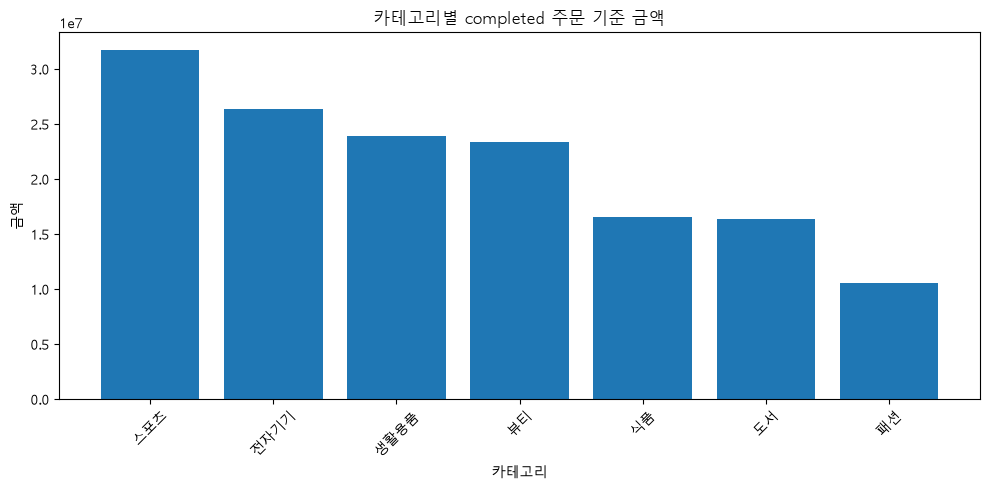

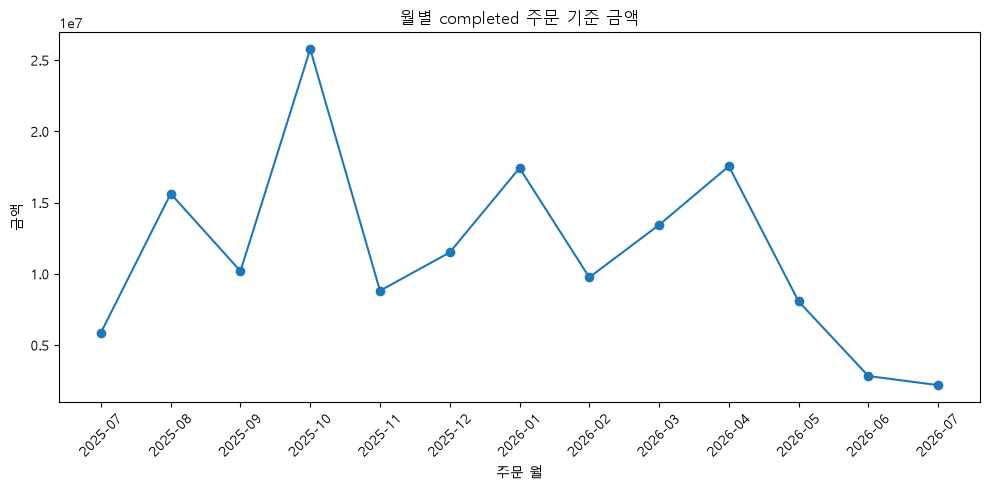

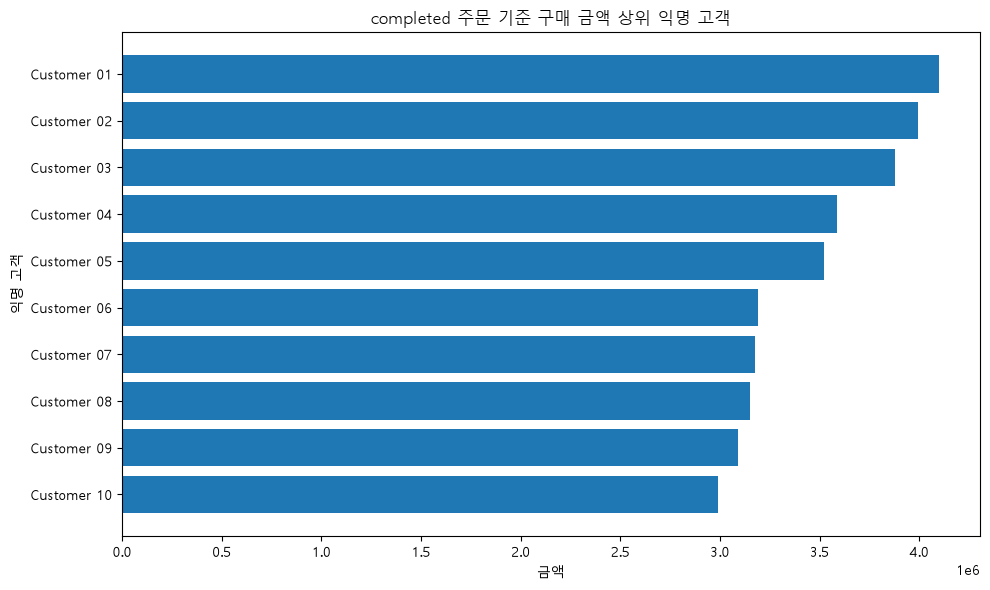

ch08_category_sales.png True 28333
ch08_monthly_sales.png True 75220
ch08_top_customers.png True 47302


In [13]:
saved_figures = create_project_figures(
    analysis_tables,
    FIGURE_DIR,
    show=True,
)

for path in saved_figures:
    print(path.name, path.exists(), path.stat().st_size)


## 14. Markdown 보고서 생성

보고서에는 계산 기준, PK/FK·병합, `line_total`, total consistency, 개인정보, 최종 Validation을 함께 남깁니다.


In [14]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / "ch08_midterm_report.md"
report_path.write_text(report_text, encoding="utf-8")

print("보고서 저장:", report_path)
print(report_text[:1800])


보고서 저장: C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\reports\ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 목적

온라인 쇼핑몰 데이터를 사용해 completed 주문 기준 금액과 고객 구매 패턴을 분석했습니다.

## 2. 분석 기준

- 금액성 분석은 `order_status == "completed"`인 주문만 포함했습니다.
- `line_total = quantity × unit_price` 관계를 검증했습니다.
- 취소·환불 등 non-completed 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.
- 공개 고객 결과에서는 이름·연락처·원본 고객 ID를 제외하고 순위 기반 익명 라벨을 사용했습니다.
- 병합은 관계 검증, `validate`, 행 수, 미매칭을 확인했습니다.
- 같은 completed 범위의 카테고리·월·고객 총합을 source total과 대조했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       150            6      

## 15. 전체 파이프라인 재실행

단계별 셀을 확인한 뒤에는 `run_midterm_project()`로 원본부터 보고서까지 다시 실행합니다. Notebook의 이전 메모리 상태에 의존하지 않는지 확인하는 단계입니다.


In [15]:
project_result = run_midterm_project(
    raw_dir=RAW_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figure_dir=FIGURE_DIR,
    show_figures=False,
)

display(project_result["project_validation"])
project_result["report_path"]


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


WindowsPath('C:/Users/82105/Desktop/대5/llm-data-analysis-study/llm-data-analysis-study/reports/ch08_midterm_report.md')

## 16. 최종 산출물 검증

필수 CSV·PNG·Markdown이 존재하고 비어 있지 않은지 확인합니다.


In [16]:
expected_outputs = [
    REPORT_DIR / "ch08_midterm_report.md",
    REPORT_DIR / "ch08_dataset_summary.csv",
    REPORT_DIR / "ch08_preprocessing_comparison.csv",
    REPORT_DIR / "ch08_key_duplicate_checks.csv",
    REPORT_DIR / "ch08_relationship_checks.csv",
    REPORT_DIR / "ch08_merge_checks.csv",
    REPORT_DIR / "ch08_line_total_check.csv",
    REPORT_DIR / "ch08_date_checks.csv",
    REPORT_DIR / "ch08_amount_scope_summary.csv",
    REPORT_DIR / "ch08_total_consistency_check.csv",
    REPORT_DIR / "ch08_project_validation.csv",
    REPORT_DIR / "ch08_category_sales.csv",
    REPORT_DIR / "ch08_monthly_sales.csv",
    REPORT_DIR / "ch08_customer_sales.csv",
    REPORT_DIR / "ch08_order_status_summary.csv",
    REPORT_DIR / "ch08_interpretation_notes.csv",
    FIGURE_DIR / "ch08_category_sales.png",
    FIGURE_DIR / "ch08_monthly_sales.png",
    FIGURE_DIR / "ch08_top_customers.png",
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, "OK" if valid else "MISSING OR EMPTY")

assert all_outputs_valid
print("전체 산출물 검증: PASS")


ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_line_total_check.csv OK
ch08_date_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_total_consistency_check.csv OK
ch08_project_validation.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_interpretation_notes.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: PASS


## 17. LLM 검토 프롬프트 예시

원본 고객 행이나 직접 식별정보 대신 비식별 검증 Evidence를 제공합니다.

```text
온라인 쇼핑몰 중간 프로젝트 결과를 검토해 주세요.

계산 기준:
- line_total = quantity × unit_price
- 금액성 분석은 order_status == completed만 사용

검증 결과:
- PK 결측/중복: 0
- FK 미매칭: 0
- merge checks: PASS
- category/month/customer totals: source total과 일치
- completed 주문 날짜 오류: 0
- 공개 고객 CSV에 원본 customer_id 없음

다음을 검토해 주세요.
1. 아직 확인하지 않은 분석 위험
2. 과도한 해석이 될 수 있는 표현
3. 보고서에 반드시 적어야 할 계산 기준
4. 추가로 필요한 검증
5. 데이터에 없는 원인은 추정하지 않기
```

LLM은 검토 범위를 넓히는 도구이지 프로젝트의 최종 승인자가 아닙니다.


## 18. 실습 과제

1. 핵심 EDA 결과 3개를 선택하고 각각 근거와 한계를 작성합니다.
2. 대표 그래프 2~4개를 선택하고 원본 집계값과 일치하는지 확인합니다.
3. `ch08_total_consistency_check.csv`와 `ch08_project_validation.csv`를 확인합니다.
4. 공개 고객 CSV에 개인정보가 없는지 다시 확인합니다.
5. LLM을 사용했다면 목적·Prompt 요약·제안·반영 여부·사람의 검증 근거를 기록합니다.
6. `python scripts/run_midterm_project.py`로 전체 프로젝트를 다시 실행하고 Notebook의 핵심 수치와 비교합니다.


In [ ]:
# 실습 과제 코드를 아래에 작성하세요.

# 최종 보고서

## 1. 분석 질문

1. 완료된 주문에서 카테고리별 평균 실판매 단가와 판매 수량은 어떤 관계를 보이는가?
2. 월별 완료 주문 금액과 주문 건수는 함께 어떻게 변화하며, 두 지표는 어떤 관계를 보이는가?
3. 월별 취소·환불 주문 건수와 전체 주문 중 비중은 어떻게 변화하는가?

## 2. 데이터와 계산 범위

### 분석 범위

- 분석 대상 기간: 주문일 기준으로 2025년 7월부터 2026년 7월까지
- 금액과 판매 수량 분석 시 order_status == "completed"인 주문만 포함
- 주문 금액 = 주문 상세의 quantity × unit_price 합산
- 주문 건수: 주문 상세 행 수가 아닌 고유 order_id 수로 계산
- 취소·환불 분석: 완료 주문으로 한정하지 않고 전체 주문을 대상으로
- 월별 취소율과 환불률 = 해당 월 전체 주문 건수를 분모로 계산

### 사용할 데이터와 지표

- 사용 데이터
    - products.csv: 상품 ID와 카테고리
    - order_items.csv: 주문 ID, 상품 ID, 수량, 주문 당시 단가
    - orders.csv: 주문 ID, 주문일, 주문 상태
    - customers.csv는 이번 세 분석 질문에 직접 사용하지 않는다.

- 계산 지표
    - 카테고리별 평균 실판매 단가: 완료 주문의 line_total 합계 ÷ 완료 주문의 판매 수량 합계 (line_total = quantity × unit_price; 수량을 반영한 가중 평균 단가)
    - 카테고리별 판매 수량: 완료 주문의 quantity 합계
    - 월별 완료 주문 금액: 해당 월 완료 주문의 line_total 합계
    - 월별 완료 주문 건수: 해당 월 완료 주문의 고유 order_id 수
    - 월별 평균 주문 금액: 월별 완료 주문 금액 ÷ 월별 완료 주문 건수
    - 월별 취소 주문 건수·취소율: 취소 주문의 고유 order_id 수, 취소 건수 ÷ 해당 월 전체 주문 건수
    - 월별 환불 주문 건수·환불률: 환불 주문의 고유 order_id 수, 환불 건수 ÷ 해당 월 전체 주문 건수
    - 관계 확인: 카테고리별 평균 단가와 판매 수량은 산점도와 Spearman 상관계수로 살펴보고, 월별 금액과 주문 건수는 시계열 그래프와 상관계수로 함께 움직이는 양상을 확인한다. 이 결과는 관계를 보여줄 뿐, 한 지표가 다른 지표의 원인이라고 증명하지는 않는다.

### 계산 기준
- `order_status == "completed"` 적용 여부: 카테고리별 평균 실판매 단가·판매 수량 및 월별 완료 주문 금액·주문 건수에 적용한다. 취소·환불 주문 건수와 비율은 해당 상태를 집계해야 하므로 전체 주문을 대상으로 계산한다.
- `line_total = quantity × unit_price` 확인 여부: Notebook 검증 결과 764개 주문 상세 행에서 불일치 0건으로 PASS였다. 분석 다시 실행 시 이 관계를 재검증하고자 한다.
- 카테고리별 평균 실판매 단가는 완료 주문의 line_total 합계를 판매 수량 합계로 나눈 가중 평균으로 계산한다. 

### 완료 기준

- PK 결측·중복과 FK 미매칭이 없고, 병합 검증과 line_total 검증이 PASS임을 확인했다.
- 카테고리별 및 월별 완료 주문 금액의 합계가 completed 원천 금액과 일치함을 확인했다. 
- 월별 분석에 사용한 주문일 오류가 없는지도 확인할 예정이다. 
- 결과와 해석에서 관찰된 관계와 원인 주장을 구분한다. 위 검증과 결과 확인을 마치면 분석을 완료한 것으로 판단한다. 

## 3. 전처리 검증

In [25]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicated rows:", int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


In [26]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)

preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)

for path in processed_paths:
    print(path, "OK" if path.exists() else "MISSING")


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\data\processed\customers_clean.csv OK
C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\data\processed\products_clean.csv OK
C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\data\processed\orders_clean.csv OK
C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\data\processed\order_items_clean.csv OK


## 2. 입력 데이터와 전처리 검증
- 사용 원본 파일: products.csv, order_items.csv, orders.csv
- shape: (100, 4), (764, 5), (300, 5)
- 핵심 결측/중복 결과: 

missing values: 0
duplicated rows: 0

- 전처리 전후 변화: 

dataset	/ rows_raw	/ columns_raw	/ rows_processed	/ columns_processed
- order_items	764	5	764	6
- orders	300	5	300	7
- products	100	4	100	4

![입력 데이터 검증](images/step02_data_validation.png)

### 나의 해석과 판단

입력한 세 테이블은 상품 100행, 주문 상세 764행, 주문 300행이며, 결측값과 완전 중복 행은 모두 0건이다. 전처리 후에도 각 테이블의 행 수가 유지되어, 전처리 과정에서 행이 누락되거나 불필요하게 늘어나지는 않았다.
이번 EDA의 계산에는 상품·주문 상세·주문 테이블을 사용한다. 다만 customers.csv를 분석 지표에서 제외하더라도 전체 FK 검증을 수행할 때는 orders.customer_id가 고객 테이블을 올바르게 참조하는지 확인하기 위해 고객 테이블을 함께 불러와야 한다.

### 한계와 추가 확인 사항

결측값과 완전 중복 행이 0건이라는 사실만으로 PK의 유일성이나 FK의 유효성이 확인되는 것은 아니다. PK별 결측·중복 및 FK 미매칭을 별도의 검증표로 확인해야 한다. 또한 행 수와 열 수 비교는 전처리 결과의 기본 점검이므로, 추가된 열의 내용과 order_date 변환 상태도 확인할 필요가 있다.

분석 기간은 2025년 7월부터 2026년 7월까지다. 첫 달과 마지막 달의 관측 기간이 온전한지 확인하지 않으면 월별 비교가 달라질 수 있다. 월별 분석 전 날짜 변환 오류를 검사하고, 오류가 있다면 해당 행을 임의로 제외하지 말고 원인과 처리 방법을 기록한다. 마지막으로, customers.csv는 EDA 지표 계산에서는 제외하지만 orders.customer_id의 FK 검증에는 사용한다.

## 4. PK/FK·병합 검증

In [27]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data).copy()

if not relationship_checks.empty:
    relationship_checks["status"] = (
        relationship_checks["invalid_count"]
        .eq(0)
        .map({True: "PASS", False: "FAIL"})
    )

display(key_duplicate_checks)
display(relationship_checks)

assert key_duplicate_checks["status"].eq("PASS").all(), "PK Validation 실패"
assert (
    not relationship_checks.empty
    and relationship_checks["invalid_count"].eq(0).all()
), "FK Validation 실패"

print("PK/FK Gate: PASS")


,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


,check,invalid_count,status
0,orders.customer_id exists in customers.custome...,0,PASS
1,order_items.order_id exists in orders.order_id,0,PASS
2,order_items.product_id exists in products.prod...,0,PASS


PK/FK Gate: PASS


In [28]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables["merge_checks"])
display(analysis_tables["line_total_check"])
display(analysis_tables["date_checks"])
display(analysis_tables["amount_scope_summary"])

assert analysis_tables["merge_checks"]["status"].eq("PASS").all()
assert analysis_tables["line_total_check"]["status"].eq("PASS").all()

print("병합 / line_total Gate: PASS")


,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → orders,many_to_one,764,764,True,0,PASS
1,product_id → products,many_to_one,474,474,True,0,PASS
2,customer_id → customers,one_to_one,100,100,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing,764,0,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.0,PASS


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_non_completed,106620000.0,290


병합 / line_total Gate: PASS


### PK 결과
- 결측: missing_count가 모두 0으로 PASS다.
- 중복: duplicate_count가 모두 0으로 PASS다. 
- PASS/FAIL: 모두 PASS

### FK 결과
- 미매칭: invalid_count = 0
- PASS/FAIL: 모두 PASS임을 확인했다. 

### 병합 결과
- validate 관계: 
1. order_id → orders (many_to_one)
2. product_id → products (many_to_one) 
3. customer_id → customers (one_to_one)
- 병합 전 행 수:
1. 764
2. 474
3. 100
- 병합 후 행 수:
1. 764
2. 474
3. 100
- 미매칭:
1. unmatched_count = 0
2. unmatched_count = 0
3. unmatched_count = 0
- PASS/FAIL:
1. PASS
2. PASS
3. PASS

### 나의 해석과 판단

PK별 결측과 중복이 모두 0건이고 FK 미매칭도 없어, 병합에 필요한 키 관계가 검증 기준을 통과했다. 각 병합에서 검증된 관계(many_to_one, one_to_one)가 성립했고, 병합 전후 행 수도 각각 764행, 474행, 100행으로 유지됐다. 미매칭도 모두 0건이므로 병합 과정에서 행이 누락되거나 키 중복으로 행이 불어나는 문제는 확인되지 않았다.

따라서 이 병합 결과를 후속 집계에 사용할 수 있다고 판단했다. 특히 완료 주문 상세와 상품을 연결한 474행은 카테고리 분석의 입력 범위와 일치한다.

다만 이 검증은 키의 결측·중복·연결 여부와 병합 행 수를 확인한 것이다. 데이터 값 자체의 업무상 정확성이나 분석 결과의 원인까지 보증하지는 않으므로, line_total과 날짜 검증 및 집계 총합 대조도 별도로 확인해야 한다.

## 5. 핵심 EDA 결과

In [20]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Image

orders = processed_data["orders"].copy()
items = processed_data["order_items"].copy()
products = processed_data["products"].copy()

# 전체 주문의 날짜를 먼저 확인합니다.
orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")
invalid_orders = orders.loc[orders["order_date"].isna()]

invalid_date_amount = items.loc[
    items["order_id"].isin(invalid_orders["order_id"]), "line_total"
].sum()

print("주문일 오류 주문 수:", invalid_orders["order_id"].nunique())
print("주문일 오류 영향 금액:", invalid_date_amount)

# 날짜 오류가 있으면 월별 집계의 날짜 범위가 불완전할 수 있으므로 중단합니다.
assert invalid_orders.empty, "주문일 오류를 먼저 확인하고 처리하세요."

orders["order_month"] = orders["order_date"].dt.to_period("M").astype(str)

# 주문 상태 및 카테고리를 상세 행에 연결합니다.
lines = (
    items
    .merge(
        orders[["order_id", "order_date", "order_month", "order_status"]],
        on="order_id",
        how="left",
        validate="many_to_one",
        indicator="_order_merge",
    )
    .merge(
        products[["product_id", "category"]],
        on="product_id",
        how="left",
        validate="many_to_one",
        indicator="_product_merge",
    )
)

assert lines["_order_merge"].eq("both").all(), "주문 병합 미매칭 발생"
assert lines["_product_merge"].eq("both").all(), "상품 병합 미매칭 발생"
assert np.allclose(
    lines["line_total"],
    lines["quantity"] * lines["unit_price"],
), "line_total 계산 불일치"

completed = lines.loc[lines["order_status"].eq("completed")].copy()

# 결과 1: 카테고리별 가중 평균 실판매 단가와 판매 수량
category_eda = (
    completed.groupby("category", as_index=False)
    .agg(
        total_quantity=("quantity", "sum"),
        total_sales=("line_total", "sum"),
    )
)
category_eda["avg_unit_price"] = (
    category_eda["total_sales"] / category_eda["total_quantity"]
)
category_eda["sales_ratio"] = (
    category_eda["total_sales"] / category_eda["total_sales"].sum() * 100
).round(2)

category_spearman = category_eda[
    ["avg_unit_price", "total_quantity"]
].corr(method="spearman").iloc[0, 1]

# 결과 2: 월별 완료 주문 금액과 고유 주문 건수
monthly_eda = (
    completed.groupby("order_month", as_index=False)
    .agg(
        total_sales=("line_total", "sum"),
        order_count=("order_id", "nunique"),
    )
    .sort_values("order_month")
)
monthly_eda["avg_order_value"] = (
    monthly_eda["total_sales"] / monthly_eda["order_count"]
)
monthly_pearson = monthly_eda[
    ["total_sales", "order_count"]
].corr(method="pearson").iloc[0, 1]

# 결과 3: 전체 주문 기준 월별 취소·환불 주문 건수와 비율
status_counts = (
    orders.groupby(["order_month", "order_status"])["order_id"]
    .nunique()
    .unstack(fill_value=0)
)

for status in ["completed", "cancelled", "refunded"]:
    if status not in status_counts.columns:
        status_counts[status] = 0

monthly_status_eda = (
    status_counts[["completed", "cancelled", "refunded"]]
    .copy()
)
monthly_status_eda["total_orders"] = (
    orders.groupby("order_month")["order_id"].nunique()
)
monthly_status_eda["cancelled_rate_pct"] = (
    monthly_status_eda["cancelled"]
    / monthly_status_eda["total_orders"] * 100
).round(2)
monthly_status_eda["refunded_rate_pct"] = (
    monthly_status_eda["refunded"]
    / monthly_status_eda["total_orders"] * 100
).round(2)
monthly_status_eda = monthly_status_eda.reset_index()

# 기존 결과와 새 재집계의 기본 수치를 대조합니다.
def verify_columns(expected, existing, key, columns, label):
    merged = expected[[key] + columns].merge(
        existing[[key] + columns],
        on=key,
        how="outer",
        suffixes=("_new", "_existing"),
        indicator=True,
    )
    assert merged["_merge"].eq("both").all(), f"{label}: 집계 대상 불일치"

    for col in columns:
        np.testing.assert_allclose(
            merged[f"{col}_new"].to_numpy(dtype=float),
            merged[f"{col}_existing"].to_numpy(dtype=float),
            rtol=0,
            atol=0.01,
            err_msg=f"{label}: {col} 불일치",
        )
    print(f"{label}: PASS")

# 이 비교는 기존 표의 수량·금액이 새 집계와 같은지 확인합니다.
verify_columns(
    category_eda, category_sales, "category",
    ["total_quantity", "total_sales"], "카테고리 수량·금액"
)
verify_columns(
    monthly_eda, monthly_sales, "order_month",
    ["total_sales", "order_count"], "월별 금액·주문 수"
)

# 총액 대조
completed_source_total = completed["line_total"].sum()
assert np.isclose(category_eda["total_sales"].sum(), completed_source_total)
assert np.isclose(monthly_eda["total_sales"].sum(), completed_source_total)

print("카테고리별 단가-수량 Spearman 상관계수:", round(category_spearman, 3))
print("월별 금액-주문 수 Pearson 상관계수:", round(monthly_pearson, 3))
print("completed 원천 금액:", f"{completed_source_total:,.0f}원")
display(category_eda)
display(monthly_eda)
display(monthly_status_eda)

주문일 오류 주문 수: 0
주문일 오류 영향 금액: 0
카테고리 수량·금액: PASS
월별 금액·주문 수: PASS
카테고리별 단가-수량 Spearman 상관계수: -0.214
월별 금액-주문 수 Pearson 상관계수: 0.955
completed 원천 금액: 148,990,000원


,category,total_quantity,total_sales,avg_unit_price,sales_ratio
0,도서,149,16389000,109993.288591,11.00
1,뷰티,223,23383000,104856.502242,15.69
2,생활용품,272,23915000,87922.794118,16.05
3,스포츠,295,31743000,107603.389831,21.31
4,식품,133,16573000,124609.022556,11.12
5,전자기기,259,26400000,101930.501931,17.72
6,패션,111,10587000,95378.378378,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-07,5869000,8,7.336250e+05
1,2025-08,15621000,18,8.678333e+05
2,2025-09,10190000,13,7.838462e+05
3,2025-10,25766000,26,9.910000e+05
4,2025-11,8812000,12,7.343333e+05
5,2025-12,11501000,14,8.215000e+05
6,2026-01,17423000,22,7.919545e+05
7,2026-02,9749000,17,5.734706e+05
8,2026-03,13429000,14,9.592143e+05
9,2026-04,17553000,23,7.631739e+05


order_status,order_month,completed,cancelled,refunded,total_orders,cancelled_rate_pct,refunded_rate_pct
0,2025-07,8,3,4,15,20.00,26.67
1,2025-08,18,5,1,24,20.83,4.17
2,2025-09,13,6,4,23,26.09,17.39
3,2025-10,26,10,3,39,25.64,7.69
4,2025-11,12,4,7,23,17.39,30.43
5,2025-12,14,9,3,26,34.62,11.54
6,2026-01,22,3,4,29,10.34,13.79
7,2026-02,17,5,7,29,17.24,24.14
8,2026-03,14,6,1,21,28.57,4.76
9,2026-04,23,5,3,31,16.13,9.68


### 결과 1

- 수치/표: 완료 주문 기준 카테고리별 평균 실판매 단가와 판매 수량은 다음과 같다.

| 카테고리 | 평균 실판매 단가 | 판매 수량 |
|---|---:|---:|
| 스포츠 | 107,603원 | 295개 |
| 전자기기 | 101,931원 | 259개 |
| 생활용품 | 87,923원 | 272개 |
| 뷰티 | 104,857원 | 223개 |
| 식품 | 124,609원 | 133개 |
| 도서 | 109,993원 | 149개 |
| 패션 | 95,378원 | 111개 |

카테고리 7개를 대상으로 계산한 Spearman 상관계수는 약 -0.214다.

- 결과 관찰: 기존 분석 질문 '완료된 주문에서 카테고리별 평균 실판매 단가와 판매 수량은 어떤 관계를 보이는가?'는 '평균 실판매 단가가 높을수록 판매 수량이 적을 수 있다'는 가정에서 비롯되었다. 해당 예상과 같은 음의 방향은 나타났지만, 그 관계는 약하다. 예를 들어 평균 단가가 가장 높은 식품은 판매량이 133개였지만, 평균 단가가 가장 낮은 생활용품의 판매량은 272개였다. 반면 판매량이 가장 많은 스포츠의 평균 단가는 107,603원으로 가장 낮지는 않았다. 따라서 단가가 높아질수록 판매량이 일관되게 줄어드는 패턴은 확인되지 않았다.
- 나의 해석과 판단: 카테고리 평균을 비교한 결과, 단가와 판매 수량 사이에 약한 음의 순위 관계가 관찰됐다. 이는 처음의 가정과 방향은 같지만, 상관계수의 크기가 작고 카테고리별 사례도 서로 달라 “단가가 높아서 판매량이 줄었다”고 결론 내릴 수는 없다.
- 업무·분석적 의미: 카테고리 평균 단가만으로 판매 수량을 예상하기는 어렵다. 가격과 판매량의 관계를 더 정확히 보려면 카테고리별 차이를 고려하면서 상품 단위의 가격과 판매 수량을 함께 살펴볼 필요가 있다.
- 한계: 분석 단위가 상품이 아니라 카테고리 평균 7개이므로, 이 결과를 개별 상품의 가격 변화에 대한 수요 반응으로 해석할 수 없다. 할인, 상품 구성, 재고 등 다른 요인도 포함되지 않아 가격이 판매량에 미친 영향을 분리해 확인할 수 없다.

### 결과 2

- 수치/표: 월별 완료 주문 금액과 고유 주문 건수는 다음과 같다.

| 월 | 완료 주문 금액 | 완료 주문 건수 |
|---|---:|---:|
| 2025-07 | 5,869,000원 | 8 |
| 2025-08 | 15,621,000원 | 18 |
| 2025-09 | 10,190,000원 | 13 |
| 2025-10 | 25,766,000원 | 26 |
| 2025-11 | 8,812,000원 | 12 |
| 2025-12 | 11,501,000원 | 14 |
| 2026-01 | 17,423,000원 | 22 |
| 2026-02 | 9,749,000원 | 17 |
| 2026-03 | 13,429,000원 | 14 |
| 2026-04 | 17,553,000원 | 23 |
| 2026-05 | 8,063,000원 | 11 |
| 2026-06 | 2,826,000원 | 4 |
| 2026-07 | 2,188,000원 | 2 |

13개월 자료에서 월별 금액과 주문 건수의 Pearson 상관계수는 약 0.955다.

- 결과 관찰: 월별 금액과 주문 건수는 대체로 같은 방향으로 움직였다. 2025년 10월이 25,766,000원, 26건으로 가장 컸고, 2026년 7월이 2,188,000원, 2건으로 가장 작았다.
- 나의 해석과 판단: 이 기간에는 주문 건수가 많은 달에 완료 주문 금액도 큰 경향이 나타났다. 다만 금액은 주문 건수뿐 아니라 주문당 금액에도 영향을 받는다.
- 업무·분석적 의미: 월별 주문 건수와 평균 주문 금액을 함께 모니터링하면 금액 변화가 주문 빈도와 주문당 금액 중 어느 쪽과 함께 움직이는지 파악하는 데 도움이 된다.
- 한계: 상관계수는 13개월 관측치에 대한 기술적 요약이다. 기간이 짧고 첫 달·마지막 달의 관측 완전성이 확인되지 않았으며, 주문 건수가 금액 변화의 원인이라는 뜻은 아니다.

### 결과 3

- 수치/표: 취소 주문 건수는 2025년 10월에 10건으로 가장 많았고, 취소율은 2026년 6월에 37.50%(6/16)로 가장 높았다. 취소율이 가장 낮은 달은 2026년 5월로 5.00%(1/20)였다. 환불 주문 건수와 환불율은 모두 2026년 5월에 가장 높아 8건, 40.00%(8/20)였다. 환불율이 가장 낮은 달은 2025년 8월로 4.17%(1/24)였다.

- 결과 관찰: 취소 건수가 가장 많았던 2025년 10월(10건)의 취소율은 25.64%였지만, 취소율은 주문 수가 더 적은 2026년 6월에 더 높았다. 환불은 2026년 5월에 8건으로 건수와 비율 모두 가장 높았다. 2026년 7월은 전체 주문이 4건뿐이어서 취소 1건과 환불 1건이 각각 25.00%로 나타났다.

- 나의 해석과 판단: 월별 건수와 비율은 다르게 움직일 수 있어 함께 봐야 한다. 2025년 10월에는 전체 주문이 39건으로 많아 취소 건수도 가장 많았지만, 전체 주문 중 취소 비율이 가장 높은 달은 아니었다. 반면 2026년 6월에는 16건 중 취소와 환불이 각각 6건으로, 두 비율 모두 37.50%였다. 2026년 5월은 환불 8건이 전체 20건의 40.00%를 차지해 상대적으로 두드러졌다.

- 업무·분석적 의미: 취소 건수만으로 우선순위를 정하기보다 월별 비율도 함께 모니터링할 필요가 있다. 이 결과에서는 2026년 5월 환불과 2026년 6월 취소·환불 내역을 후속 점검 대상으로 삼을 수 있다.

- 한계: 월별 주문 건수가 적은 달에는 몇 건의 변화만으로 비율이 크게 달라질 수 있다. 특히 2026년 7월은 전체 주문이 4건뿐이므로 25.00%라는 비율을 안정적인 월별 특성으로 해석하기 어렵다. 이 집계만으로 취소·환불의 원인이나 금액 영향을 알 수 없고, 관측 기간이 13개월이므로 장기 추세라고 단정할 수도 없다.

## 6. total consistency

In [29]:
total_consistency = analysis_tables["total_consistency_check"]
display(total_consistency)

assert total_consistency["matches_completed"].all(), "Total consistency Gate 실패"
assert analysis_tables["date_checks"]["status"].eq("PASS").all(), "날짜 Gate 실패"

print("Total consistency / Date Gate: PASS")


,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


Total consistency / Date Gate: PASS


## 5. Total consistency와 날짜 검증

- completed source total: 148,990,000원
- category total: 148,990,000원
- monthly total: 148,990,000원
- customer total: 148,990,000원
- 총합 일치 여부: 네 합계가 모두 일치하며 `ch08_total_consistency_check.csv`의 차이는 0원, 상태는 PASS다.
- completed 주문 날짜 오류 건수: 0건
- 날짜 오류 영향 금액: 0원

### 불일치가 있었다면 원인

불일치는 확인되지 않았다. 합계가 다를 경우 completed 필터 적용 여부, 병합으로 인한 행 증가 또는 미매칭, 카테고리·고객 연결 누락, 주문일 변환 실패, 서로 다른 집계 범위의 사용 여부를 점검한다.

## 7. 대표 시각화

C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\chapter08\images\graph01.png True 41925


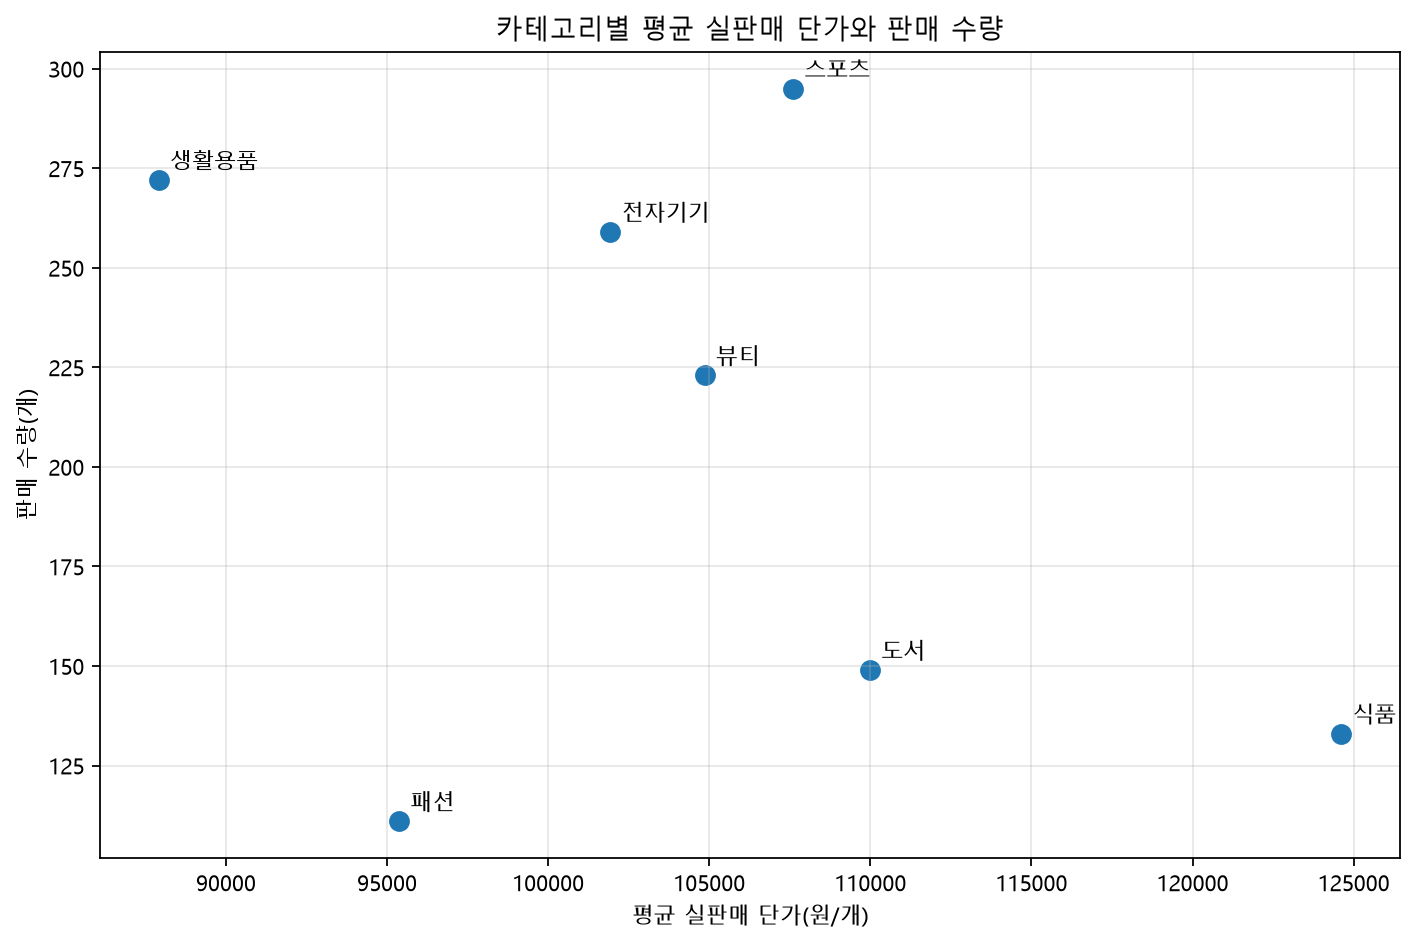

C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\chapter08\images\graph02.png True 117837


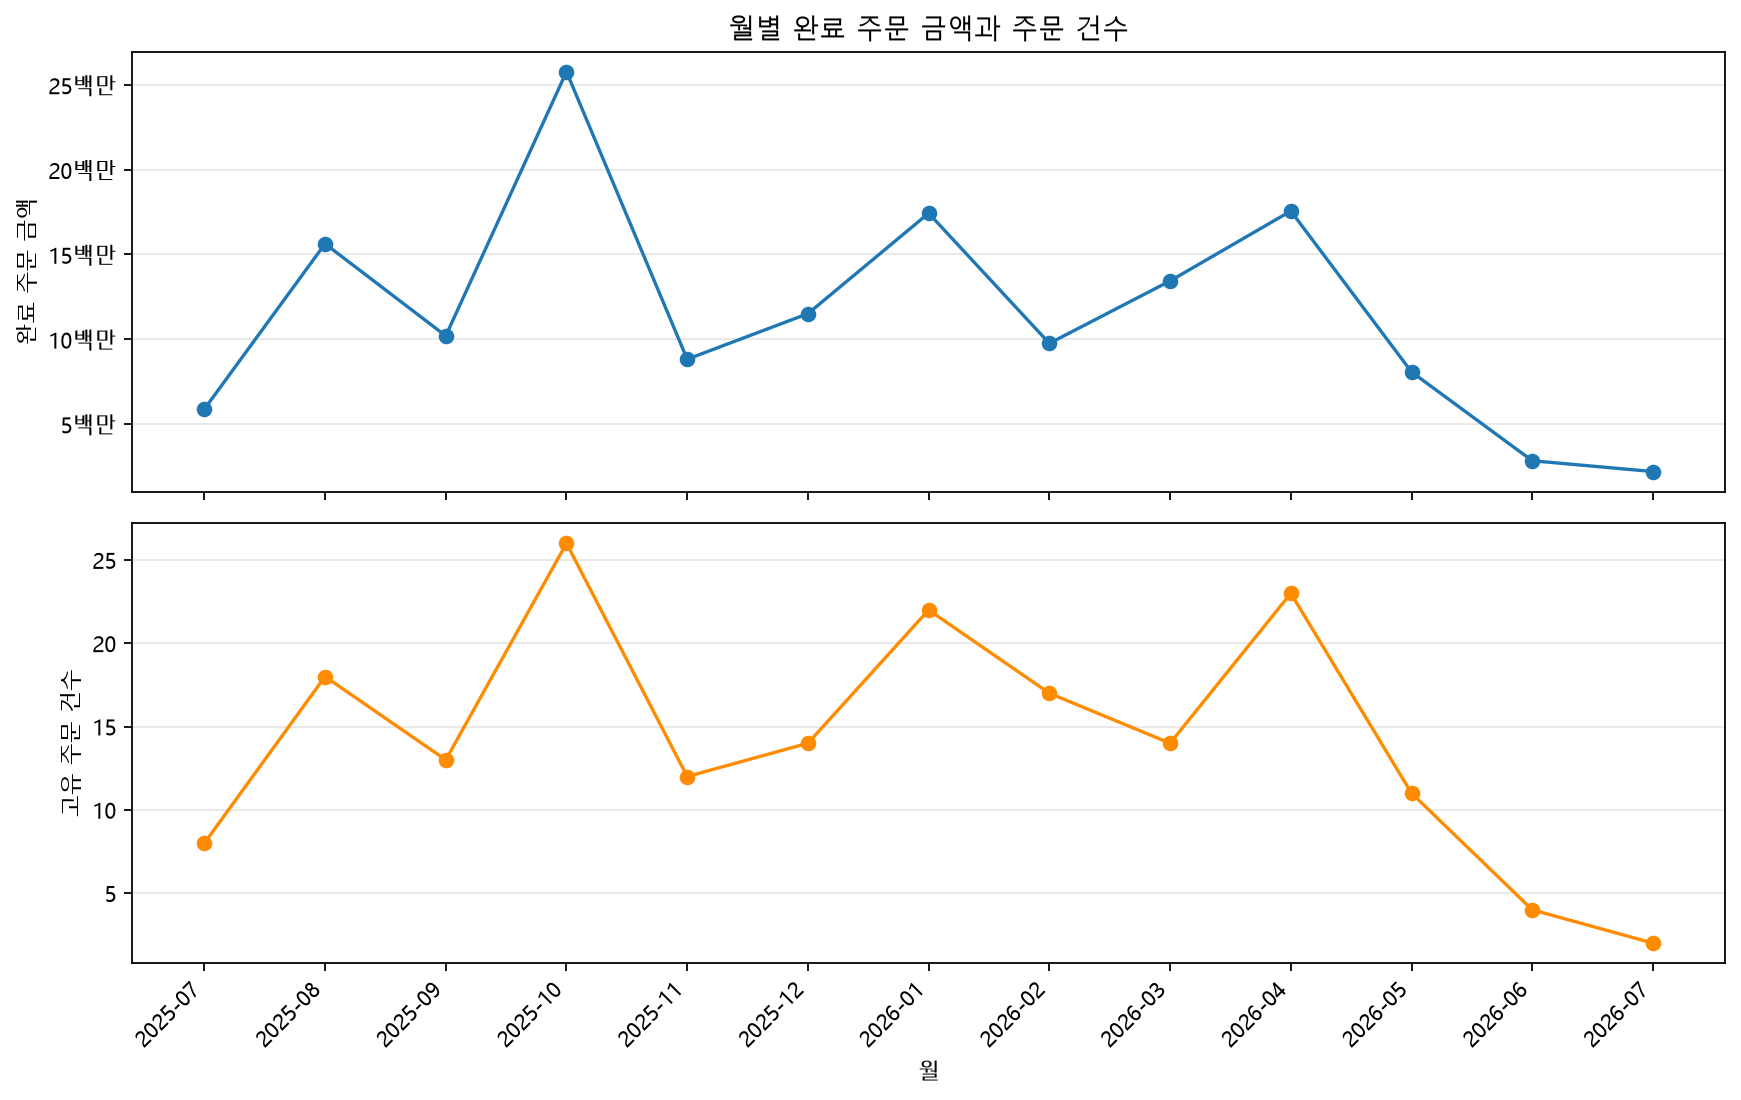

C:\Users\82105\Desktop\대5\llm-data-analysis-study\llm-data-analysis-study\chapter08\images\graph03.png True 135413


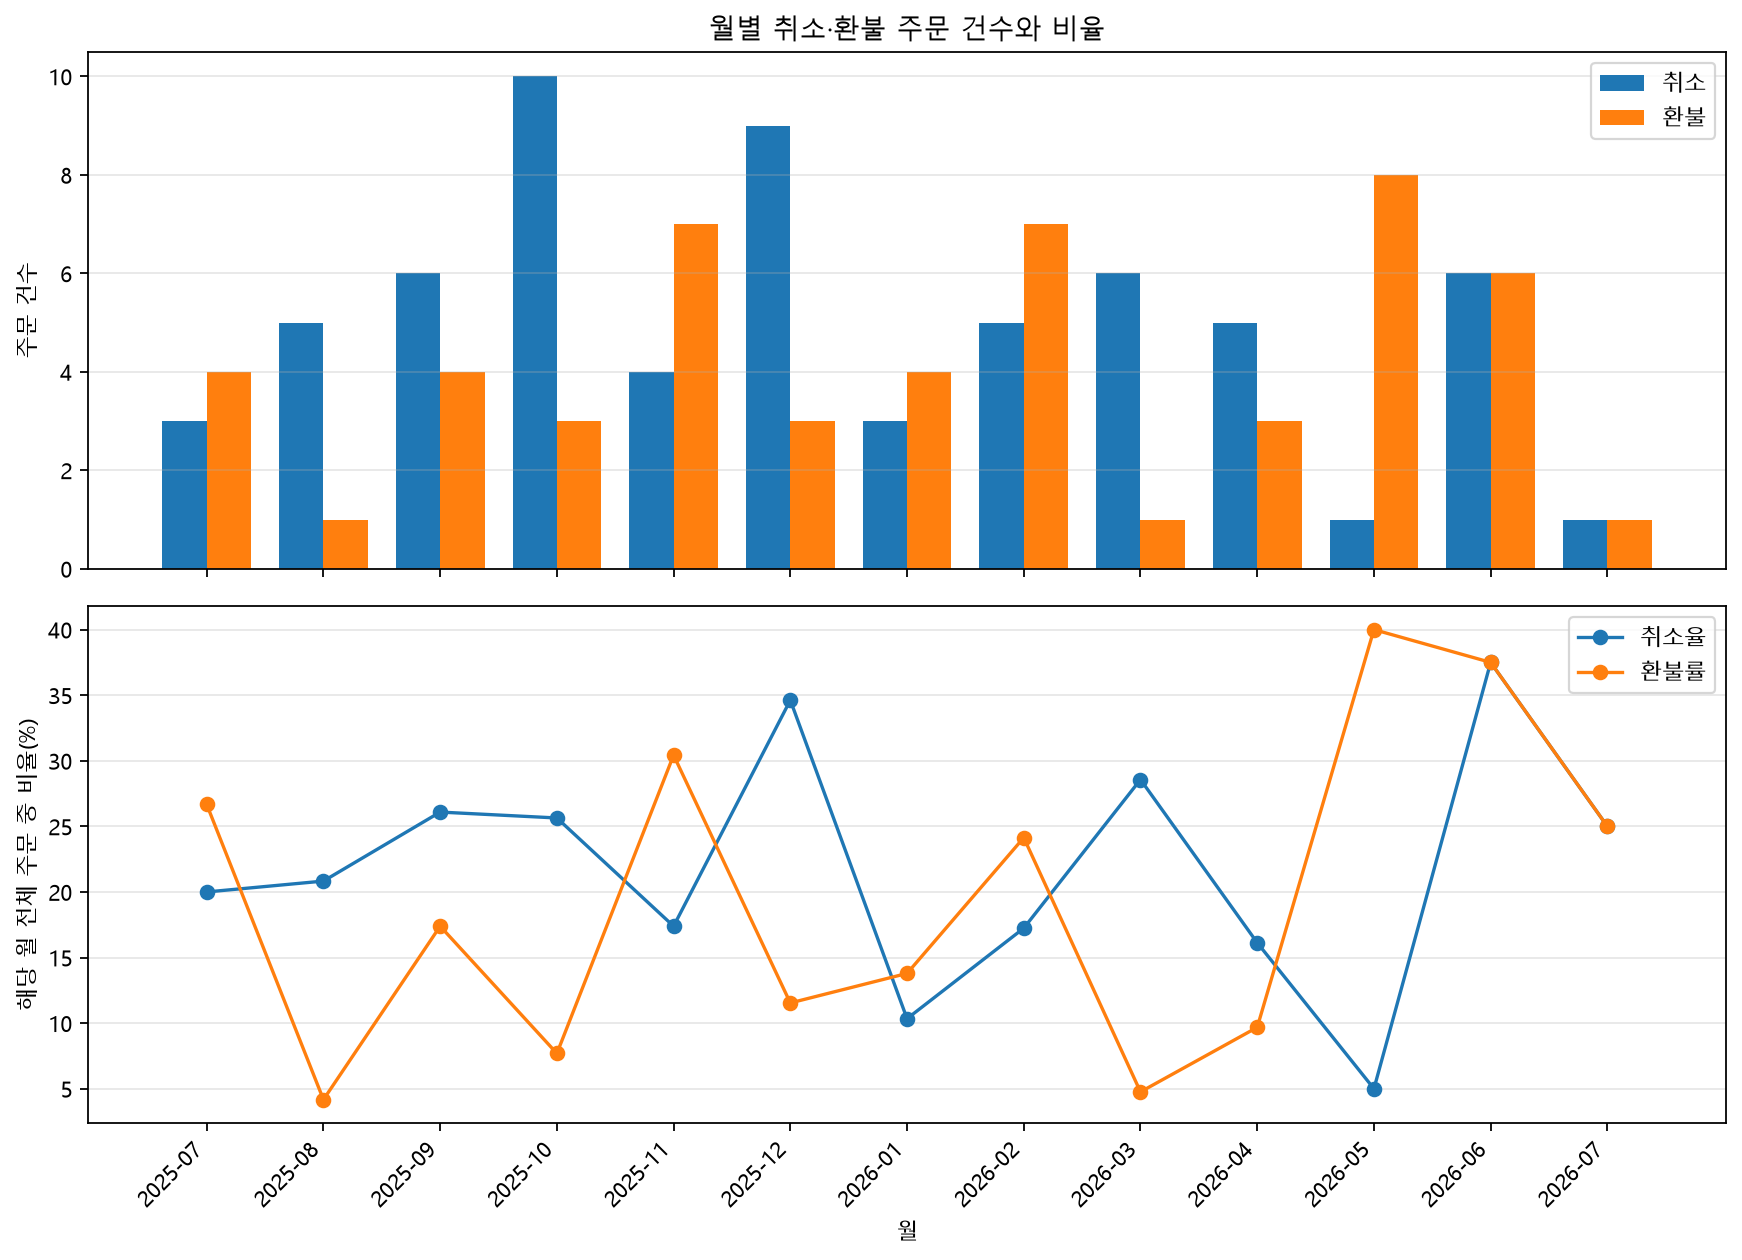

In [30]:
# 한글 폰트 설정
for font_name in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    try:
        font_manager.findfont(font_name, fallback_to_default=False)
        plt.rcParams["font.family"] = font_name
        break
    except ValueError:
        pass

plt.rcParams["axes.unicode_minus"] = False

IMAGE_DIR = PROJECT_ROOT / "chapter08" / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

won_millions = FuncFormatter(lambda value, _: f"{value / 1_000_000:.0f}백만")

# 그래프 1: 카테고리별 평균 단가와 판매 수량
plot1 = category_eda.sort_values("avg_unit_price")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(plot1["avg_unit_price"], plot1["total_quantity"], s=70)

for _, row in plot1.iterrows():
    ax.annotate(
        row["category"],
        (row["avg_unit_price"], row["total_quantity"]),
        xytext=(5, 5),
        textcoords="offset points",
    )

ax.set_title("카테고리별 평균 실판매 단가와 판매 수량")
ax.set_xlabel("평균 실판매 단가(원/개)")
ax.set_ylabel("판매 수량(개)")
ax.grid(alpha=0.3)
fig.tight_layout()
graph01_path = IMAGE_DIR / "graph01.png"
fig.savefig(graph01_path, dpi=160, bbox_inches="tight")
plt.close(fig)

# 그래프 2: 월별 completed 주문 금액과 고유 주문 건수
fig, (ax_sales, ax_orders) = plt.subplots(
    2, 1, figsize=(11, 7), sharex=True
)
ax_sales.plot(
    monthly_eda["order_month"],
    monthly_eda["total_sales"],
    marker="o",
)
ax_sales.set_title("월별 완료 주문 금액과 주문 건수")
ax_sales.set_ylabel("완료 주문 금액")
ax_sales.yaxis.set_major_formatter(won_millions)
ax_sales.grid(axis="y", alpha=0.3)

ax_orders.plot(
    monthly_eda["order_month"],
    monthly_eda["order_count"],
    marker="o",
    color="darkorange",
)
ax_orders.set_ylabel("고유 주문 건수")
ax_orders.set_xlabel("월")
ax_orders.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
graph02_path = IMAGE_DIR / "graph02.png"
fig.savefig(graph02_path, dpi=160, bbox_inches="tight")
plt.close(fig)

# 그래프 3: 월별 취소·환불 건수와 각 비율
fig, (ax_counts, ax_rates) = plt.subplots(
    2, 1, figsize=(11, 8), sharex=True
)

x = np.arange(len(monthly_status_eda))
width = 0.38

ax_counts.bar(
    x - width / 2,
    monthly_status_eda["cancelled"],
    width,
    label="취소",
)
ax_counts.bar(
    x + width / 2,
    monthly_status_eda["refunded"],
    width,
    label="환불",
)
ax_counts.set_ylabel("주문 건수")
ax_counts.set_title("월별 취소·환불 주문 건수와 비율")
ax_counts.legend()
ax_counts.grid(axis="y", alpha=0.3)

ax_rates.plot(
    x,
    monthly_status_eda["cancelled_rate_pct"],
    marker="o",
    label="취소율",
)
ax_rates.plot(
    x,
    monthly_status_eda["refunded_rate_pct"],
    marker="o",
    label="환불률",
)
ax_rates.set_xticks(x)
ax_rates.set_xticklabels(monthly_status_eda["order_month"], rotation=45, ha="right")
ax_rates.set_ylabel("해당 월 전체 주문 중 비율(%)")
ax_rates.set_xlabel("월")
ax_rates.legend()
ax_rates.grid(axis="y", alpha=0.3)

fig.tight_layout()
graph03_path = IMAGE_DIR / "graph03.png"
fig.savefig(graph03_path, dpi=160, bbox_inches="tight")
plt.close(fig)

for path in [graph01_path, graph02_path, graph03_path]:
    print(path, path.exists(), path.stat().st_size)
    display(Image(filename=str(path)))

### 그래프 선택 이유

그래프 1은 카테고리별 평균 실판매 단가와 판매 수량을 산점도로 나타내어, 단가가 높은 카테고리에서 판매 수량이 적은 경향이 있는지 살펴보기 위해 선택했다. 그래프 2는 월별 완료 주문 금액과 고유 주문 건수를 각각의 패널에 표시해 두 지표의 변화 양상을 비교한다. 그래프 3은 월별 취소·환불 건수와 전체 주문 중 비율을 함께 보여주어, 건수와 비율이 어떻게 달라지는지 확인할 수 있다.

### 그래프와 원본 집계값 일치 여부

그래프 1은 `category_eda`, 그래프 2는 `monthly_eda`, 그래프 3은 `monthly_status_eda`에서 계산한 값을 사용한다. 카테고리와 월별 완료 주문 금액 합계는 각각 completed 원천 금액과 대조했고, 그래프 3의 주문 건수와 비율은 월별 고유 주문 수를 분모로 계산했다.

### 그래프에서 직접 관찰한 사실

그래프 1에서는 평균 실판매 단가가 높은 카테고리의 판매 수량이 대체로 적은 방향이 일부 보이지만, 카테고리별 점들이 일관된 순서로 놓이지는 않는다. 이는 Spearman 상관계수 약 -0.214와도 맞으며, 관찰된 음의 관계는 약한 수준이다. 그래프 2에서는 월별 완료 주문 금액과 주문 수가 대체로 같은 방향으로 변한다. 그래프 3에서는 월별 취소·환불 건수와 비율의 움직임을 비교해 볼 수 있으며, 높은 건수와 높은 비율이 항상 같은 달에 나타나는지는 집계표를 기준으로 확인한다.

### 그래프만으로 말할 수 없는 것

그래프 1만으로 단가가 판매 수량을 줄였다고 결론 내릴 수 없다. 분석 대상이 카테고리 평균 7개이므로 개별 상품의 가격과 판매량 관계를 설명한다고 볼 수도 없다. 그래프 2의 동행 양상과 높은 상관계수도 주문 수가 매출을 증가시켰다는 인과관계를 증명하지 않는다. 그래프 3은 취소·환불 변동을 보여주지만 그 원인을 설명하지는 않는다. 특히 전체 주문이 4건인 2026년 7월의 25% 비율은 분모가 작아 다른 달과 비교할 때 주의가 필요하다.

## 8. 개인정보 검증

In [23]:
import re
import pandas as pd

customer_csv_path = REPORT_DIR / "ch08_customer_sales.csv"
saved_customer = pd.read_csv(customer_csv_path)

# 컬럼명 표기 차이를 정규화합니다.
def normalize_column(column):
    return re.sub(r"[^a-z0-9]", "", str(column).lower())

# 프로젝트에 정의된 금지 컬럼과 흔히 쓰는 직접 식별정보 컬럼명을 함께 검사합니다.
direct_pii_aliases = {
    "customer_id", "name", "customer_name", "full_name",
    "email", "email_address",
    "phone", "phone_number", "telephone", "mobile",
    "address", "street_address",
}
forbidden_names = {
    normalize_column(column)
    for column in FORBIDDEN_CUSTOMER_COLUMNS
} | {
    normalize_column(column)
    for column in direct_pii_aliases
}

memory_forbidden = sorted(
    column
    for column in customer_sales_public.columns
    if normalize_column(column) in forbidden_names
)
saved_forbidden = sorted(
    column
    for column in saved_customer.columns
    if normalize_column(column) in forbidden_names
)

# 공개용으로 허용한 컬럼 구성인지 확인합니다.
expected_public_columns = {
    "customer_label",
    "city",
    "order_count",
    "total_sales",
    "avg_order_value",
}
schema_ok = set(saved_customer.columns) == expected_public_columns

# 라벨이 원본 ID가 아닌 순위형 익명 라벨인지 확인합니다.
labels = saved_customer["customer_label"].astype(str)
labels_are_anonymous = labels.str.fullmatch(r"Customer \d{2,}").all()
labels_are_unique = labels.is_unique

print("저장된 공개 고객 CSV 컬럼:", saved_customer.columns.tolist())
print("메모리 결과의 금지 컬럼:", memory_forbidden)
print("저장 CSV의 금지 컬럼:", saved_forbidden)
print("예상 공개 스키마 일치:", schema_ok)
print("순위형 익명 라벨 형식·고유성:", labels_are_anonymous and labels_are_unique)

privacy_pass = (
    not memory_forbidden
    and not saved_forbidden
    and schema_ok
    and labels_are_anonymous
    and labels_are_unique
)

assert privacy_pass, "Privacy Gate 실패"
print("Privacy Gate: PASS")

저장된 공개 고객 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
메모리 결과의 금지 컬럼: []
저장 CSV의 금지 컬럼: []
예상 공개 스키마 일치: True
순위형 익명 라벨 형식·고유성: True
Privacy Gate: PASS


- 공개 고객 CSV 컬럼: `customer_label`, `city`, `order_count`, `total_sales`, `avg_order_value`
- 원본 `customer_id` 포함 여부: 포함하지 않았다.
- 이름/이메일/전화번호/주소 포함 여부: 포함하지 않았다.
- 익명 라벨 방식: 원본 ID를 공개 라벨에 사용하지 않고 `Customer 01`, `Customer 02`와 같은 순위형 라벨을 사용했다.
- PASS/FAIL: 저장된 `ch08_customer_sales.csv`를 다시 읽어 확인했으며, 금지 컬럼이 없어 PASS다.

### 나의 판단

공개 고객 CSV에서 원본 고객 ID와 이름·연락처·주소 등 직접 식별정보가 제외됐고, 고객 라벨도 순위형 익명 라벨로 저장됐다. 다만 `city`는 공개 컬럼에 포함되어 있다. 도시 정보는 직접 식별자는 아니지만 다른 정보와 결합될 경우 개인을 추정하는 데 쓰일 수 있으므로, 외부 공개 범위가 넓다면 제거하거나 더 넓은 지역 단위로 묶는 것을 검토한다. 이 검증은 주로 컬럼과 라벨 형식을 확인한 것이며, 모든 재식별 가능성을 평가한 것은 아니다.

## 9. 핵심 인사이트 (최종 Validation)

In [24]:
# 결과 1: 카테고리 평균 단가와 판매 수량
assert (category_eda["total_quantity"] > 0).all()
np.testing.assert_allclose(
    category_eda["avg_unit_price"] * category_eda["total_quantity"],
    category_eda["total_sales"],
    rtol=0,
    atol=0.01,
)
assert category_eda["category"].is_unique

# 결과 2: 월별 completed 금액과 주문 수
assert monthly_eda["order_month"].is_unique
assert monthly_eda["order_count"].sum() == completed["order_id"].nunique()
assert np.isclose(
    monthly_eda["total_sales"].sum(),
    completed["line_total"].sum(),
)

# 결과 3: 모든 주문 상태의 월별 집계와 비율
status_cols = ["completed", "cancelled", "refunded"]
assert monthly_status_eda["total_orders"].eq(
    monthly_status_eda[status_cols].sum(axis=1)
).all()

np.testing.assert_allclose(
    monthly_status_eda["cancelled_rate_pct"],
    monthly_status_eda["cancelled"]
    / monthly_status_eda["total_orders"] * 100,
    rtol=0,
    atol=0.01,
)
np.testing.assert_allclose(
    monthly_status_eda["refunded_rate_pct"],
    monthly_status_eda["refunded"]
    / monthly_status_eda["total_orders"] * 100,
    rtol=0,
    atol=0.01,
)

# 결과 3은 전체 주문을 사용하므로 모든 주문의 날짜를 확인
all_order_dates = pd.to_datetime(orders["order_date"], errors="coerce")
assert all_order_dates.notna().all(), "전체 주문 중 날짜 오류가 있습니다."

print("사용자 정의 EDA 검증: PASS")

사용자 정의 EDA 검증: PASS


`reports/ch08_project_validation.csv`의 결과를 요약합니다.

| 검증 항목 | 결과 | 내가 확인한 근거 |
| --- | --- | --- |
| pk_integrity | all PASS | `ch08_key_duplicate_checks.csv`에서 4개 PK의 결측·중복이 모두 0이고 상태가 PASS임을 확인 |
| fk_integrity | 0 | `ch08_relationship_checks.csv`에서 3개 FK 관계의 `invalid_count`가 모두 0임을 확인 |
| merge_checks_pass | all PASS | `ch08_merge_checks.csv`에서 3개 병합의 관계 검증이 PASS이고, 전후 행 수가 유지되며 미매칭이 0임을 확인 |
| line_total_consistency | 0 | `ch08_line_total_check.csv`에서 764개 행의 `mismatch_count`가 0임을 확인 |
| completed_total_consistency | all match | `ch08_total_consistency_check.csv`에서 원천·카테고리·월별·고객 금액이 각각 148,990,000원이고 차이가 0임을 확인 |
| category_sales_ratio_pct_sum | 100 | `ch08_category_sales.csv`의 `sales_ratio` 합계가 100.0%임을 확인 |
| completed_rows_with_invalid_order_date | 0 | `ch08_date_checks.csv`에서 completed 주문 날짜 오류 0건, 영향 금액 0원임을 확인 |
| public_customer_columns_safe | no forbidden columns | 저장된 `ch08_customer_sales.csv`를 다시 읽어 금지 컬럼이 없음을 확인 |

### FAIL이 있었다면 수정 내용

FAIL 항목은 없었다. 위 검증 항목은 모두 PASS였다. 사용자 정의 EDA의 별도 검증은 이 표와 별도로 실행해 결과를 확인했다.

## 10. LLM 활용 기록

- 사용 여부: 사용함.
- 사용 목적: 분석 질문을 과제 형식에 맞게 다듬고, EDA 재집계·검증 코드와 시각화 코드를 작성하며 결과 해석 초안을 정리하는 데 사용했다.
- Safe Context: 분석 질문, 테이블 구조, 집계된 카테고리·월별 금액과 주문 수, 익명 고객 집계, 검증 Gate 결과를 제공했다. 원본 고객 행이나 고객 ID·이름·이메일·전화번호·주소는 제공하지 않았다.
- Prompt 요약: 카테고리별 평균 실판매 단가와 판매 수량, 월별 완료 주문 금액과 주문 건수, 월별 취소·환불 주문 건수와 비율을 계산·시각화하고, 검증 방법과 해석의 한계를 작성하도록 요청했다.
- 제안 요약: 평균 단가는 완료 주문 금액을 판매 수량으로 나눈 가중 평균으로 계산하고, 주문 수는 고유 `order_id`로 세도록 제안했다. 취소율과 환불율은 월별 전체 주문 건수를 분모로 계산하고, 관찰과 원인 주장을 구분하도록 제안했다.
- 반영/수정/보류: 사용자의 세 분석 질문과 일치하는 지표 및 그래프를 반영했다. 예시의 고객별 구매 금액 EDA는 수정된 질문과 달라 최종 핵심 EDA에서 제외했다. 평균 주문 금액 비교에서 발생한 소수점 반올림 차이는 원 단위 반올림 기준을 적용하도록 수정했다.
- 사람이 검증한 근거: 재집계 결과를 기존 표와 대조하는 과정에서 평균 주문 금액의 반올림 차이를 확인했다. 월별 취소·환불 집계값을 직접 확인했고, Notebook의 최종 Validation 출력에서 제시된 항목이 모두 PASS인 것도 확인했다.


### ! LLM 검토 프롬프트

온라인 쇼핑몰 프로젝트의 EDA 결과와 검증 근거를 검토해 주세요. 아래에 제공한 집계값과 검증 결과만 사용하고, 데이터에 없는 원인은 추정하지 마세요.

### 분석 질문과 계산 기준

1. 완료 주문에서 카테고리별 평균 실판매 단가와 판매 수량은 어떤 관계를 보이는가?
   - 평균 실판매 단가 = completed 주문의 `line_total` 합계 ÷ 판매 수량 합계
   - `line_total = quantity × unit_price`
2. 월별 completed 주문 금액과 고유 주문 건수는 함께 어떻게 변화하는가?
3. 월별 취소·환불 주문 건수와 해당 월 전체 주문 중 비중은 어떻게 변화하는가?
   - 취소율·환불율의 분모는 해당 월 전체 고유 주문 건수다.

### 비식별 집계 결과

- 카테고리별 분석은 7개 카테고리를 대상으로 했다. 평균 단가와 판매 수량의 Spearman 상관계수는 약 -0.214다. 카테고리별 판매 수량은 111~295개, 평균 실판매 단가는 약 87,923~124,609원이다.
- 월별 completed 금액과 고유 주문 건수는 2025년 7월부터 2026년 7월까지 13개월을 대상으로 했다. 두 지표의 Pearson 상관계수는 약 0.955다. 월별 주문 건수는 2~26건이다.
- 취소 건수는 2025년 10월에 10건으로 가장 많았다. 취소율은 2026년 6월에 37.50%(6/16)로 가장 높았고, 2026년 5월에 5.00%(1/20)로 가장 낮았다.
- 환불 건수와 환불율은 2026년 5월에 가장 높았다: 8건, 40.00%(8/20). 환불율은 2025년 8월에 4.17%(1/24)로 가장 낮았다.
- 월별 전체 주문 건수는 4~39건이다. 특히 2026년 7월은 4건뿐이다.

### 프로젝트 검증 결과

- PK 결측·중복: 모두 0, PASS
- FK 미매칭: 0, PASS
- 병합 검증: 모두 PASS
- 764개 주문 상세 행의 `line_total` 불일치: 0
- completed source, 카테고리, 월별, 고객별 금액 합계: 각각 148,990,000원으로 일치
- 카테고리 매출 비중 합계: 100.0%
- built-in completed 주문 날짜 오류: 0
- 별도 월별 취소·환불 집계는 전체 주문의 날짜를 기준으로 계산했다.
- 공개 고객 CSV 컬럼: `customer_label`, `city`, `order_count`, `total_sales`, `avg_order_value`. 원본 `customer_id`, 이름, 이메일, 전화번호, 주소는 포함하지 않는다. `city`는 남아 있다.

### 검토 요청

1. 세 분석 질문과 지표·집계 단위가 서로 맞는지 검토해 주세요.
2. 상관계수와 월별 변화를 해석할 때 표본 수, 집계 수준, 주문 건수 차이 때문에 주의할 점을 짚어 주세요.
3. 특히 월별 주문 수가 적은 달의 취소율·환불율을 어떻게 제한적으로 해석해야 하는지 검토해 주세요.
4. 결론에서 과도한 주장이나 인과관계 표현이 있는지 찾아, 더 신중한 대체 표현을 제안해 주세요.
5. 그래프의 값이 집계표와 일치하는지 확인하기 위해 필요한 검증을 제안해 주세요.
6. 프로젝트 Gate 외에 이 세 분석 질문에 맞춰 추가해야 할 검증이 있는지 알려 주세요.
7. 공개 고객 결과에 남은 `city` 정보의 잠재적 재식별 위험과 추가 보호 방법을 검토해 주세요.

원인, 프로모션 효과, 고객 선호, 수익성 등 제공된 집계로 확인할 수 없는 내용을 사실처럼 추정하지 마세요. 사실 관찰, 해석, 후속 가설을 구분해 답해 주세요.

### ! 검토 결과

세 질문은 지표와 집계 단위가 대체로 맞습니다. 해석은 모두 **관찰된 관계**로 제한하고, 원인이나 예측으로 확대하지 않는 것이 좋습니다.

1. **카테고리별 평균 실판매 단가와 판매 수량:** 가중 평균 단가 정의와 카테고리 단위가 질문에 맞습니다. Spearman 상관계수 -0.214는 이 7개 카테고리에서 약한 음의 순위 관계를 보인다는 뜻입니다. 단가가 높을수록 판매량이 감소한다고 결론 내릴 근거는 아닙니다. 카테고리는 7개뿐이고, 집계값이라 개별 상품의 가격·판매량 관계도 드러나지 않습니다.

2. **월별 완료 주문 금액과 주문 건수:** 월별 `line_total` 합계와 고유 `order_id` 수를 함께 보는 것은 질문에 맞습니다. Pearson 상관계수 0.955는 13개월 동안 두 지표가 강한 양의 방향으로 함께 움직였음을 보여줍니다. 다만 주문 건수가 늘면 합산 금액도 커질 수 있는 구조이므로, 주문 건수가 금액 증가의 원인이라고 해석하면 안 됩니다. 월별 평균 주문 금액도 함께 살펴보는 것이 유용합니다.

3. **월별 취소·환불 주문 건수와 비율:** 전체 주문을 대상으로 하고 월별 전체 고유 주문 수를 분모로 사용한 것은 질문에 맞습니다. 취소 건수는 2025년 10월에 10건으로 가장 많지만, 취소율은 2026년 6월에 37.50%(6/16)로 가장 높습니다. 환불 건수와 비율은 2026년 5월에 각각 8건, 40.00%(8/20)로 가장 높습니다. 건수와 비율을 함께 보여주는 것이 적절합니다.

### 해석 시 주의할 점

월별 전체 주문 수는 4~39건으로 달마다 차이가 큽니다. 2026년 7월은 4건뿐이므로 취소 1건이나 환불 1건만으로 비율이 25%가 됩니다. 이 달의 비율을 안정적인 월별 특성으로 해석하면 안 됩니다. 2026년 5월과 6월의 높은 비율도 원인을 설명하지는 않으므로, 해당 월의 주문 세부 자료를 추가로 확인해야 합니다.

보고서에는 다음처럼 표현하면 안전합니다.

- “7개 카테고리의 집계에서 평균 실판매 단가와 판매 수량의 Spearman 상관계수는 -0.214였다. 카테고리 수가 적어 단가가 판매량에 영향을 준다고 해석하지 않았다.”
- “13개월 집계에서 월별 완료 주문 금액과 주문 건수의 Pearson 상관계수는 0.955였다. 두 지표의 동반 변화이며 인과관계를 의미하지 않는다.”
- “취소·환불 비율은 월별 주문 수에 따라 변동 폭이 커질 수 있어 건수와 분모를 함께 제시했다.”

### 추가 검증 제안

기존 프로젝트 Gate는 계속 유효하지만, 새 질문에 대한 검증을 추가해야 합니다.

- 카테고리별 `avg_unit_price × total_quantity`가 `total_sales`와 일치하는지 확인합니다.
- 월별 주문 수가 상세 행 수가 아니라 `order_id.nunique()`인지 확인합니다.
- 월별 상태별 건수의 합이 월별 전체 주문 수와 일치하는지 확인합니다.
- 취소율·환불율이 각각 `상태별 주문 수 ÷ 해당 월 전체 주문 수 × 100`으로 계산됐는지 확인합니다.
- 기존 날짜 Gate는 completed 주문의 오류를 확인하므로, 취소·환불 분석을 위해서는 **전체 주문**의 `order_date` 오류도 별도로 확인합니다.
- 그래프는 집계표에서 직접 생성하고, 그래프에 사용된 값이 집계표 값과 일치하는지 확인합니다.

### 개인정보와 공개 고객 결과

공개 고객 CSV에서 직접 식별정보가 빠진 것은 긍정적입니다. 다만 `city`와 구매 금액·주문 수가 결합되면 간접 식별에 쓰일 가능성이 있습니다. 세 분석 질문에는 고객별 결과가 필요하지 않으므로, 공개 산출물에서 `city`를 제거하거나 더 넓은 지역 단위로 묶는 방안을 검토할 수 있습니다. `Customer 01` 같은 순위형 라벨도 완전한 익명성을 보장한다고 단정하지 않는 편이 좋습니다.


## 14. 재현 방법

## 10. 프로젝트 재현 확인
- `python scripts/run_midterm_project.py` 실행 여부: 실행 완료. 터미널에 8장 중간 프로젝트 완료가 출력됐다.
- 재실행 결과: 원본 4개 데이터의 행 수는 customers 150행, products 100행, orders 300행, order_items 764행이었다. 결측과 완전 중복은 모두 0건이었다. PK·FK·병합·line_total 검증이 PASS였고, completed 주문 금액 148,990,000원이 카테고리·월별·고객별 합계와 일치했다. 최종 Validation 항목도 모두 PASS였다.
- Notebook과 핵심 수치 일치 여부: 데이터 행 수, line_total 불일치 0건, completed 원천 금액 148,990,000원, 카테고리별 금액 및 월별 completed 금액·주문 수가 Notebook 결과와 일치했다. 월별 취소·환불 건수와 비율은 실행 스크립트가 월별 표로 직접 출력하지 않으므로 별도로 대조했다. 월별 상태별 건수를 합산한 결과 completed 184건, cancelled 64건, refunded 52건으로 전체 300건과 일치했다.
- 생성된 핵심 Evidence 파일 확인 여부: ch08_total_consistency_check.csv, ch08_project_validation.csv를 포함한 주요 결과표, reports/figures/의 그래프 3개, ch08_midterm_report.md 경로가 실행 출력에 기록된 것을 확인했다.

![재실행 결과](images/step06_reproduce.png)

### 나의 해석과 판단
재실행 가능한 프로젝트가 왜 중요한지 작성하세요.

전체 프로젝트를 다시 실행해 원본 데이터부터 검증표와 결과물을 재생성할 수 있음을 확인했다. 재현 실행은 이전 실행에서 남은 메모리 상태에 의존하지 않고 같은 입력과 계산 절차로 결과를 확인하게 해 주며, 오류가 발생한 단계와 결과를 추적하는 데 도움이 된다. 이번 실행에서는 주요 Gate가 모두 PASS였고 completed 금액 집계도 일치했다. 사용자 정의 월별 취소·환불 분석은 기본 스크립트가 월별 결과를 직접 만들지 않아, 월별 집계 코드를 별도로 실행하고 전체 상태별 주문 수와 대조했다.

## 15. 최종 프로젝트 요약

### 핵심 인사이트 3개
1. 카테고리별 평균 실판매 단가와 판매 수량:
7개 카테고리에서 평균 실판매 단가는 약 87,923~124,609원, 판매 수량은 111~295개였다. 두 지표의 Spearman 상관계수는 약 -0.214로, 이 집계에서는 뚜렷한 단조 관계가 확인되지 않았다.
2. 월별 completed 주문 금액과 주문 건수:
2025년 7월부터 2026년 7월까지 13개월의 두 지표는 함께 오르내리는 양상을 보였으며 Pearson 상관계수는 약 0.955였다. 2025년 10월에는 금액 25,766,000원·26건으로 가장 컸고, 2026년 7월에는 2,188,000원·2건으로 가장 작았다.
3. 월별 취소·환불 현황:
취소 건수는 2025년 10월에 10건으로 가장 많았고, 취소율은 2026년 6월에 37.50%(6/16)로 가장 높았다. 환불 건수와 환불율은 2026년 5월에 각각 8건, 40.00%(8/20)로 가장 높았다. 월별 전체 주문이 4~39건으로 달라 비율을 비교할 때는 분모도 함께 살펴야 한다.

### 가장 중요한 업무·분석적 의미

카테고리별로 평균 단가와 판매 수량을 함께 살펴보면 상품 구성과 판매 현황을 더 구체적으로 점검할 수 있다. 월별 금액과 주문 건수가 함께 움직이는 정도를 확인하면 두 지표를 함께 모니터링할 수 있고, 취소·환불 건수와 비율은 주문 상태를 점검할 월을 찾는 데 참고할 수 있다. 다만 이 결과만으로 판매나 취소·환불의 원인을 판단할 수는 없다.

### 현재 분석의 한계

카테고리 분석은 7개, 월별 분석은 13개월을 대상으로 한 집계 결과다. 상관계수는 집계된 두 지표의 관계를 나타낼 뿐 인과관계를 설명하지 않는다. 특히 주문 수가 적은 달은 취소율·환불율이 몇 건의 변화에도 크게 달라질 수 있다. 프로모션, 가격 변경, 상품별 판매 구성, 취소·환불 사유 등 원인 판단에 필요한 정보도 이번 분석에는 포함되지 않았다.

### 다음 분석 제안
1. 월별 완료 주문 금액을 주문 건수와 평균 주문 금액으로 나누어 살펴보고, 관측 기간을 늘려 월별 패턴이 지속되는지 확인한다.
2. 상품 수준의 가격·판매 수량과 할인 정보가 있다면 카테고리 평균에 가려진 상품별 차이를 분석한다.
3. 취소·환불 사유와 주문 상품 정보를 연결해 원인을 확인하고, 월별 비율은 주문 수와 함께 제시하거나 더 긴 기간의 자료로 비교한다.

## 최종 체크
- [O] 질문과 지표가 연결됩니다.
- [O] 원본 데이터에서 다시 시작했습니다.
- [O] PK/FK·병합 검증 근거가 있습니다.
- [O] `line_total` 계산 관계를 확인했습니다.
- [O] 금액성 분석은 completed 범위를 사용했습니다.
- [O] category/month/customer 총합이 source total과 일치합니다.
- [O] 날짜 오류를 확인했습니다.
- [O] 공개 고객 결과에서 원본 ID와 직접 식별정보를 제거했습니다.
- [O] 대표 그래프와 원본 집계값을 비교했습니다.
- [O] 원인 과대 해석이 없습니다.
- [O] 최종 Validation이 모두 PASS입니다.
- [O] 전체 프로젝트를 재실행했습니다.
- [O] 한계와 다음 분석을 작성했습니다.
- [O] 최종 Notebook URL을 제출합니다.

## 정리

이번 장에서는 원본 데이터 확인, 전처리, PK/FK, 병합, `line_total`, completed 범위, total consistency, 날짜, 개인정보, 시각화, 보고서, 최종 Validation을 하나의 프로젝트로 연결했습니다.

기억할 핵심은 다음과 같습니다.

```text
실행 성공 ≠ 검증 완료
같은 의미의 숫자는 서로 다른 집계에서도 같아야 한다
공개 결과에는 불필요한 개인정보를 남기지 않는다
프로젝트는 원본부터 다시 실행할 수 있어야 한다
```
